# 02 · Erros tipo I e II, poder e dimensionamento (PUCRS)

**Prévia, não conclusão.** O notebook tem três capítulos:
1. os dois erros de um teste A/B e o que α e β controlam;
2. as duas distribuições superpostas, com as áreas de α e β;
3. as curvas de poder da PUCRS, para dimensionar o tamanho de amostra de cada KPI.

## 1. Erro tipo I e erro tipo II

Todo teste A/B parte de uma **hipótese nula**, $H_0$: *a variante não muda o KPI*. No fim, o teste rejeita ou não rejeita $H_0$. Como a realidade também tem dois estados, existem quatro combinações:

| | **Realidade: não há efeito** ($H_0$ verdadeira) | **Realidade: há efeito** ($H_1$ verdadeira) |
|---|---|---|
| **Teste: "há efeito"** (rejeita $H_0$) | ❌ **Erro tipo I**, falso positivo. Probabilidade **α** | ✅ Acerto. Probabilidade **1 − β = poder** |
| **Teste: "não há efeito"** (não rejeita $H_0$) | ✅ Acerto. Probabilidade 1 − α | ❌ **Erro tipo II**, falso negativo. Probabilidade **β** |

**α, nível de significância: controla o erro tipo I.** Se a variante *não* funciona, α é a chance de o teste dizer que funciona só por ruído de amostragem. Com α = 5%, cerca de 1 em cada 20 testes de variantes inúteis sai "significativo". No Cortex, isso é aprender uma lição falsa e propagar uma variante neutra.

**β: controla o erro tipo II.** Se a variante *funciona* com o efeito que se dimensionou, β é a chance de o teste não perceber. No Cortex, isso é descartar uma boa ideia como "não funcionou".

**Poder = 1 − β.** É a chance de detectar um efeito que existe. O poder só faz sentido atrelado a **um tamanho de efeito**: "80% de poder para detectar 15% de uplift". Para um efeito menor, o mesmo n tem menos poder.

**As quatro grandezas do desenho:** α, poder, efeito mínimo detectável (MDE) e tamanho de amostra *n*. Fixar três determina a quarta. Com *n* fixo, α e β puxam em sentidos opostos: mais rigor contra falso positivo (α menor) gera mais falso negativo (β maior). Só aumentar *n* ou reduzir a variância (por exemplo, com CUPED) diminui os dois ao mesmo tempo.

**α = 5% e poder = 80% são convenções.** Elas tratam um falso positivo como 4 vezes pior que um falso negativo. Para variantes baratas e reversíveis, como uma mensagem de WhatsApp, essa troca pode ser revista.

**Atenção: "não significativo" não é "não funciona".** O teste publicado da PUCRS deu +54% de lift, com p = 0,13 e **poder observado de 31%**. Com poder baixo, o β alto domina, e o resultado correto é *inconclusivo*.

## 2. As duas distribuições: onde ficam α e β

A curva cinza é a distribuição da estatística do teste quando **não há efeito** ($H_0$), centrada em 0. A curva colorida é a distribuição quando **o efeito existe** ($H_1$), centrada em $\delta$. O **valor crítico** $z_{1-\alpha/2}$ separa as decisões: à direita dele, o teste declara "há efeito".

- **α** (vermelho): a parte de $H_0$ que passa do valor crítico. São falsos positivos. Num teste bicaudal, α/2 fica em cada cauda.
- **β** (azul): a parte de $H_1$ que fica antes do valor crítico. São efeitos reais que o teste deixa passar.
- **Poder**: o resto de $H_1$, à direita do valor crítico.

Aumentar *n* não move o valor crítico, mas afasta $H_1$ de $H_0$: a distância $\delta$ cresce com $\sqrt{n}$. Por isso, no painel da direita, com 4× a amostra, β quase some sem mexer em α.

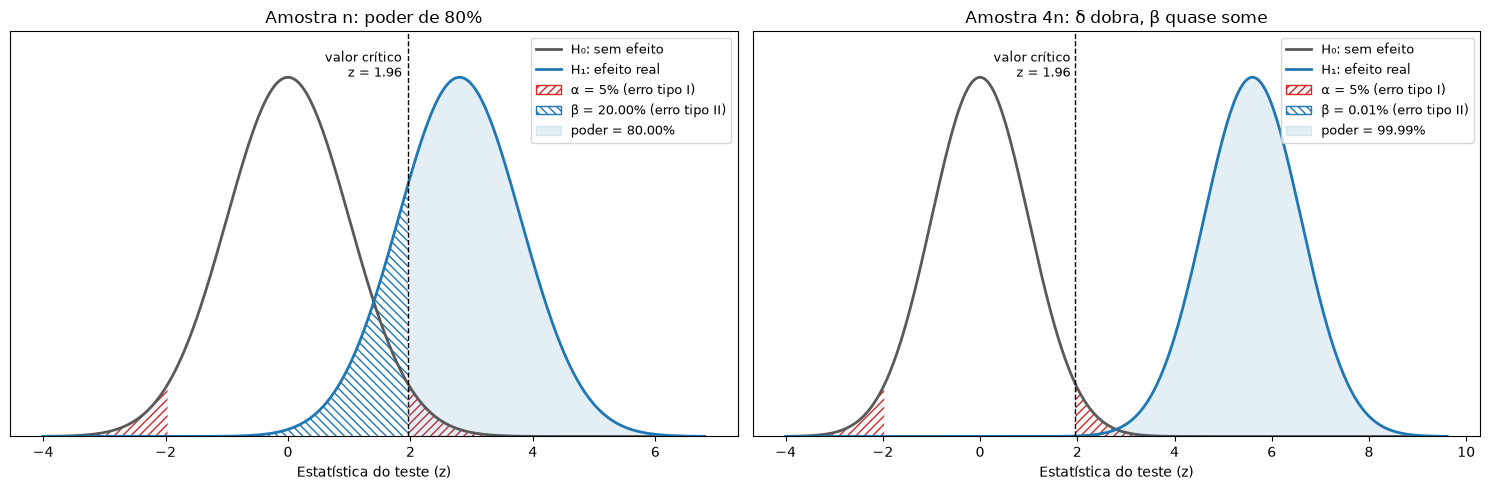

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def plot_alpha_beta(ax, delta, alpha=0.05, title=""):
    x = np.linspace(-4, delta + 4, 1000)
    z_crit = norm.ppf(1 - alpha / 2)
    h0, h1 = norm.pdf(x), norm.pdf(x, loc=delta)
    ax.plot(x, h0, color="0.35", lw=2, label="H₀: sem efeito")
    ax.plot(x, h1, color="tab:blue", lw=2, label="H₁: efeito real")
    # α: caudas de H0 além dos valores críticos
    for mask in (x >= z_crit, x <= -z_crit):
        ax.fill_between(x[mask], h0[mask], facecolor="none", edgecolor="tab:red", hatch="////", lw=0)
    # β: parte de H1 antes do valor crítico
    m = x <= z_crit
    ax.fill_between(x[m], h1[m], facecolor="none", edgecolor="tab:blue", hatch="\\\\\\\\", lw=0)
    # poder: parte de H1 depois do valor crítico
    m = x >= z_crit
    ax.fill_between(x[m], h1[m], color="tab:blue", alpha=0.12, lw=0)
    ax.axvline(z_crit, color="k", ls="--", lw=1)
    ax.text(z_crit - 0.1, 0.43, f"valor crítico\nz = {z_crit:.2f}", va="top", ha="right", fontsize=9)

    beta = norm.cdf(z_crit - delta)
    handles = [
        plt.Line2D([], [], color="0.35", lw=2, label="H₀: sem efeito"),
        plt.Line2D([], [], color="tab:blue", lw=2, label="H₁: efeito real"),
        plt.matplotlib.patches.Patch(facecolor="none", edgecolor="tab:red", hatch="////", label=f"α = {alpha:.0%} (erro tipo I)"),
        plt.matplotlib.patches.Patch(facecolor="none", edgecolor="tab:blue", hatch="\\\\\\\\", label=f"β = {beta:.2%} (erro tipo II)"),
        plt.matplotlib.patches.Patch(color="tab:blue", alpha=0.12, label=f"poder = {1 - beta:.2%}"),
    ]
    ax.legend(handles=handles, loc="upper right", fontsize=9)
    ax.set_ylim(0, 0.45)
    ax.set_xlabel("Estatística do teste (z)")
    ax.set_yticks([])
    ax.set_title(title)

ALPHA = 0.05
delta_80 = norm.ppf(1 - ALPHA / 2) + norm.ppf(0.80)  # distância que dá 80% de poder

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
plot_alpha_beta(axes[0], delta_80, ALPHA, "Amostra n: poder de 80%")
plot_alpha_beta(axes[1], 2 * delta_80, ALPHA, "Amostra 4n: δ dobra, β quase some")
plt.tight_layout()
plt.show()

## 3. PUCRS: curva de poder por KPI

O gráfico mostra o poder em função do tamanho de amostra por braço, com uma curva para cada uplift relativo. Para dimensionar, trace a reta horizontal em 80%. O ponto em que ela cruza a curva do uplift desejado dá o *n* necessário.

Teste de duas proporções, bicaudal, com aproximação normal (Fleiss, Levin & Paik, 2003, cap. 4):

$$\text{poder}(n) = \Phi\!\left(\frac{|p_2-p_1|\sqrt{n} - z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)}}{\sqrt{p_1(1-p_1)+p_2(1-p_2)}}\right),\quad p_2 = p_1(1+\text{uplift})$$

**Taxas base da PUCRS** (por par lead × campanha):
- **Resposta: 2,87%.** É o controle do teste publicado da PUCRS.
- **Compra crua em 30 dias: 0,359%.** Vem de `fct_cortex_lead_campanha`, de 17/08 a 12/10/2026.
- **Entrada:** cerca de 281.547 pares por semana.

As taxas são por par, não por lead. Como os pares de um mesmo lead não são independentes, os *n* reais tendem a ser maiores.

In [6]:
ALPHA = 0.05
TARGET_POWER = 0.80
UPLIFTS = [0.05, 0.10, 0.15, 0.20, 0.30]
PARES_POR_SEMANA = 281_547  # PUCRS

KPIS = {
    "Resposta (p₁ = 2,87%)": 0.0287,
    "Compra crua 30d (p₁ = 0,359%)": 0.00359,
}

def power(n, p1, uplift, alpha=ALPHA):
    p2 = p1 * (1 + uplift)
    pbar = (p1 + p2) / 2
    z = norm.ppf(1 - alpha / 2)
    num = abs(p2 - p1) * np.sqrt(n) - z * np.sqrt(2 * pbar * (1 - pbar))
    return norm.cdf(num / np.sqrt(p1 * (1 - p1) + p2 * (1 - p2)))

def n_required(p1, uplift, alpha=ALPHA, pw=TARGET_POWER):
    p2 = p1 * (1 + uplift)
    pbar = (p1 + p2) / 2
    za, zb = norm.ppf(1 - alpha / 2), norm.ppf(pw)
    num = za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))
    return int(np.ceil((num / (p2 - p1)) ** 2))

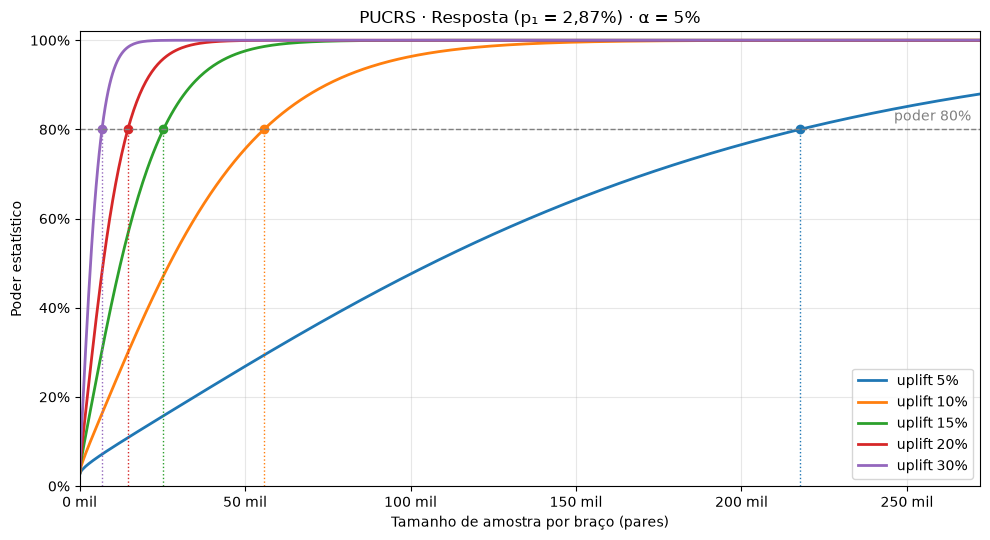

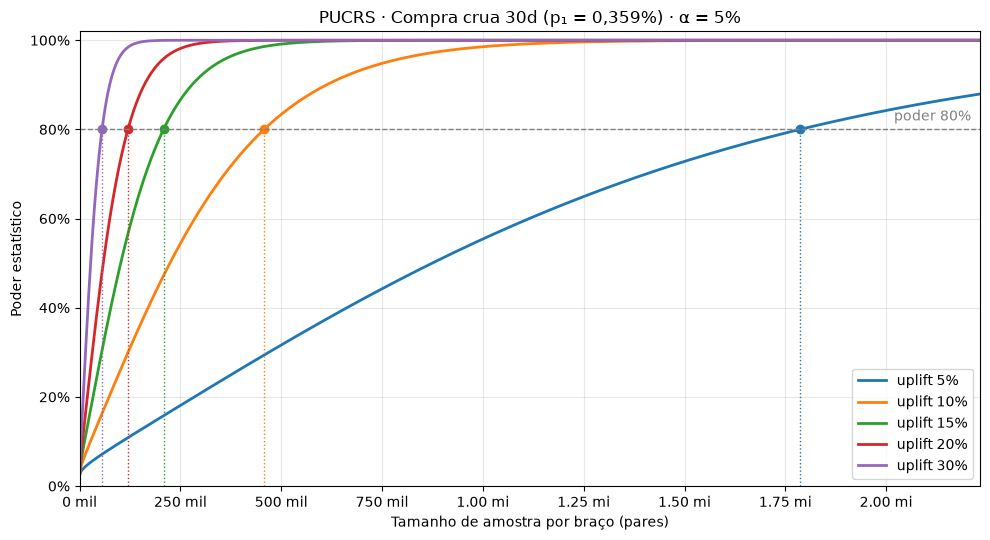

In [7]:
def plot_power_curve(label, p1, ax):
    n_max = n_required(p1, min(UPLIFTS)) * 1.25
    n = np.linspace(1, n_max, 600)
    for u in UPLIFTS:
        line, = ax.plot(n, power(n, p1, u), lw=2, label=f"uplift {u:.0%}")
        n_star = n_required(p1, u)
        ax.plot([n_star, n_star], [0, TARGET_POWER], ls=":", color=line.get_color(), lw=1)
        ax.plot(n_star, TARGET_POWER, "o", color=line.get_color())
    ax.axhline(TARGET_POWER, ls="--", color="gray", lw=1)
    ax.text(n_max * 0.99, TARGET_POWER + 0.02, "poder 80%", ha="right", color="gray")
    ax.set_xlim(0, n_max)
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e3:,.0f} mil" if x < 1e6 else f"{x/1e6:,.2f} mi"))
    ax.set_xlabel("Tamanho de amostra por braço (pares)")
    ax.set_ylabel("Poder estatístico")
    ax.set_title(f"PUCRS · {label} · α = {ALPHA:.0%}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")

for label, p1 in KPIS.items():
    fig, ax = plt.subplots(figsize=(10, 5.5))
    plot_power_curve(label, p1, ax)
    plt.tight_layout()
    plt.show()

In [8]:
# Leitura dos cruzamentos com a reta de 80%
for label, p1 in KPIS.items():
    print(label)
    for u in UPLIFTS:
        n_star = n_required(p1, u)
        semanas = 2 * n_star / PARES_POR_SEMANA
        print(f"  uplift {u:>4.0%}: n por braço = {n_star:>10,}  ->  {semanas:5.1f} semanas de entrada (2 braços)")
    print()

Resposta (p₁ = 2,87%)
  uplift   5%: n por braço =    217,656  ->    1.5 semanas de entrada (2 braços)
  uplift  10%: n por braço =     55,699  ->    0.4 semanas de entrada (2 braços)
  uplift  15%: n por braço =     25,326  ->    0.2 semanas de entrada (2 braços)
  uplift  20%: n por braço =     14,566  ->    0.1 semanas de entrada (2 braços)
  uplift  30%: n por braço =      6,758  ->    0.0 semanas de entrada (2 braços)

Compra crua 30d (p₁ = 0,359%)
  uplift   5%: n por braço =  1,786,183  ->   12.7 semanas de entrada (2 braços)
  uplift  10%: n por braço =    457,395  ->    3.2 semanas de entrada (2 braços)
  uplift  15%: n por braço =    208,108  ->    1.5 semanas de entrada (2 braços)
  uplift  20%: n por braço =    119,772  ->    0.9 semanas de entrada (2 braços)
  uplift  30%: n por braço =     55,641  ->    0.4 semanas de entrada (2 braços)

